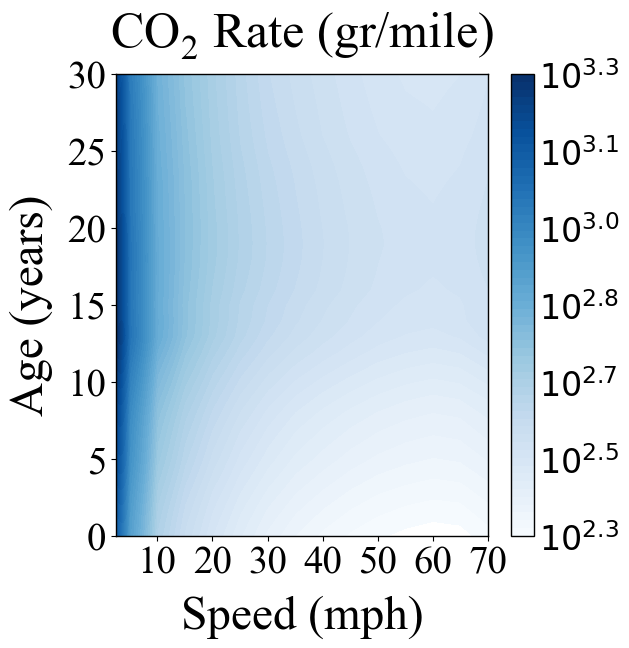

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from matplotlib.ticker import FuncFormatter
import base64
from io import BytesIO

# Load the dataset
file_path = r'C:\Users\schowdho\Downloads\NY\Paper Plot\Fig 3\CA\2024CaliforniaMovesdata_sorted_above_CO2.csv'
data = pd.read_csv(file_path)

# Replace negative values in 'Predicted CO2' column with their absolute values
data['Predicted CO2'] = data['Predicted CO2'].abs()

# Filter the DataFrame based on the specified conditions
filtered_df = data[data['Vehicle Type'] == 'Passenger Car']
gasoline_data = filtered_df[filtered_df['Fuel Type'] == 'Gasoline']

# Create a pivot table for contour plot
pivot_table = gasoline_data.pivot_table(values='Predicted CO2', index='Age', columns='Speed')

# Handle NaN values by filling them with a small number (close to zero)
pivot_table = pivot_table.fillna(1e-5)

# Set default font family to Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'

# Create the contour plot with LogNorm color scale
plt.figure(figsize=(6, 6))
# Adjust the levels for the contour plot to start from 0.1 to the max value
levels = np.logspace(np.log10(215), np.log10(pivot_table.values.max()), 60)
contour = plt.contourf(pivot_table.columns, pivot_table.index, pivot_table, cmap='Blues', levels=levels, norm=LogNorm())

# Define specific ticks for the colorbar
ticks = np.logspace(np.log10(215), np.log10(pivot_table.values.max()), num=7)
colorbar = plt.colorbar(contour, ticks=ticks)

# Function to format the colorbar ticks without dashes and without decimal points in exponents
def format_func(value, tick_number):
    exponent = np.log10(value)
    if exponent.is_integer():
        return f'$10^{{{int(exponent)}}}$'
    else:
        return f'$10^{{{exponent:.1f}}}$'

formatter = FuncFormatter(format_func)
colorbar.ax.yaxis.set_major_formatter(formatter)

# Set font sizes
axis_label_font_size = 34
x_tick_label_font_size = 28
y_tick_label_font_size = 28
colorbar_tick_label_font_size = 24
title_font_size = 36

# Set font sizes for colorbar
colorbar.ax.tick_params(labelsize=colorbar_tick_label_font_size, size=0)

# Add gray border to colorbar
colorbar.outline.set_edgecolor('black')
colorbar.outline.set_linewidth(1)

# Manually set the font size of the colorbar tick labels
for label in colorbar.ax.yaxis.get_ticklabels():
    label.set_fontsize(colorbar_tick_label_font_size)

# Set font sizes for plot labels
plt.xlabel('Speed (mph)', fontsize=axis_label_font_size, labelpad=10)
plt.ylabel('Age (years)', fontsize=axis_label_font_size, labelpad=10)
plt.title(r'$\mathregular{CO_2}$ Rate (gr/mile)', fontsize=title_font_size, pad=20, loc='center')

# Set font sizes for plot tick labels
plt.xticks(fontsize=x_tick_label_font_size)
plt.yticks(fontsize=y_tick_label_font_size)

plt.xlim(2.5, 70)
plt.ylim(0, 30)

# Set the box border color to black
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1)

# Remove grid
ax.grid(False)

# Save the plot as a PNG image to a BytesIO object
png_buffer = BytesIO()
plt.savefig(png_buffer, format='png', dpi=300, bbox_inches='tight', pad_inches=0.5)
png_buffer.seek(0)

# Encode the PNG image to base64
png_base64 = base64.b64encode(png_buffer.read()).decode('utf-8')
png_buffer.close()

# Create the SVG output with the embedded base64 PNG image
svg_output = f"""
<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1800 1800" width="1800" height="1800">
    <image href="data:image/png;base64,{png_base64}" x="0" y="0" height="1800px" width="1800px"/>
</svg>
"""

# Save the SVG file
output_svg_path = r'C:\Users\schowdho\Downloads\GA1\PLOT FIGURE\Fig_3_b_2.svg'
with open(output_svg_path, 'w', encoding='utf-8') as svg_file:
    svg_file.write(svg_output)

# Show the plot
plt.show()


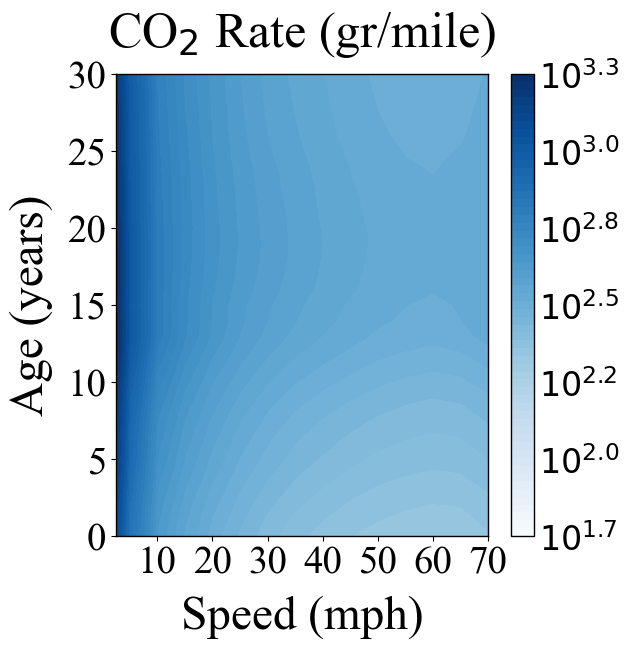

In [3]:
#Used in TRB Paper

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from matplotlib.ticker import FuncFormatter
import base64
from io import BytesIO

# Load the dataset
file_path = r'C:\Users\schowdho\Downloads\NY\Paper Plot\Fig 3\CA\2024CaliforniaMovesdata_sorted_above_CO2.csv'
data = pd.read_csv(file_path)

# Replace negative values in 'Predicted CO2' column with their absolute values
data['Predicted CO2'] = data['Predicted CO2'].abs()

# Filter the DataFrame based on the specified conditions
filtered_df = data[data['Vehicle Type'] == 'Passenger Car']
gasoline_data = filtered_df[filtered_df['Fuel Type'] == 'Gasoline']

# Create a pivot table for contour plot
pivot_table = gasoline_data.pivot_table(values='Predicted CO2', index='Age', columns='Speed')

# Handle NaN values by filling them with a small number (close to zero)
pivot_table = pivot_table.fillna(1e-5)

# Set default font family to Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'

# Create the contour plot with LogNorm color scale
plt.figure(figsize=(6, 6))
# Adjust the levels for the contour plot to start from 0.1 to the max value
levels = np.logspace(np.log10(49), np.log10(pivot_table.values.max()), 60)
contour = plt.contourf(pivot_table.columns, pivot_table.index, pivot_table, cmap='Blues', levels=levels, norm=LogNorm())

# Define specific ticks for the colorbar
ticks = np.logspace(np.log10(49), np.log10(pivot_table.values.max()), num=7)
colorbar = plt.colorbar(contour, ticks=ticks)

# Function to format the colorbar ticks without dashes and without decimal points in exponents
def format_func(value, tick_number):
    exponent = np.log10(value)
    if exponent.is_integer():
        return f'$10^{{{int(exponent)}}}$'
    else:
        return f'$10^{{{exponent:.1f}}}$'

formatter = FuncFormatter(format_func)
colorbar.ax.yaxis.set_major_formatter(formatter)

# Set font sizes
axis_label_font_size = 34
x_tick_label_font_size = 28
y_tick_label_font_size = 28
colorbar_tick_label_font_size = 24
title_font_size = 36

# Set font sizes for colorbar
colorbar.ax.tick_params(labelsize=colorbar_tick_label_font_size, size=0)

# Add gray border to colorbar
colorbar.outline.set_edgecolor('black')
colorbar.outline.set_linewidth(1)

# Manually set the font size of the colorbar tick labels
for label in colorbar.ax.yaxis.get_ticklabels():
    label.set_fontsize(colorbar_tick_label_font_size)

# Set font sizes for plot labels
plt.xlabel('Speed (mph)', fontsize=axis_label_font_size, labelpad=10)
plt.ylabel('Age (years)', fontsize=axis_label_font_size, labelpad=10)
plt.title('CO$_2$ Rate (gr/mile)', fontsize=title_font_size, pad=20, loc='center')

# Set font sizes for plot tick labels
plt.xticks(fontsize=x_tick_label_font_size)
plt.yticks(fontsize=y_tick_label_font_size)

plt.xlim(2.5, 70)
plt.ylim(0, 30)

# Set the box border color to black
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1)

# Remove grid
ax.grid(False)

# Save the plot as a PNG image to a BytesIO object
png_buffer = BytesIO()
plt.savefig(png_buffer, format='png', dpi=300, bbox_inches='tight', pad_inches=0.5)
png_buffer.seek(0)

# Encode the PNG image to base64
png_base64 = base64.b64encode(png_buffer.read()).decode('utf-8')
png_buffer.close()

# Create the SVG output with the embedded base64 PNG image
svg_output = f"""
<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1800 1800" width="1800" height="1800">
    <image href="data:image/png;base64,{png_base64}" x="0" y="0" height="1800px" width="1800px"/>
</svg>
"""

# Save the SVG file
output_svg_path = r'C:\Users\schowdho\Downloads\GA1\PLOT FIGURE\Fig_3_b_2.svg'
with open(output_svg_path, 'w', encoding='utf-8') as svg_file:
    svg_file.write(svg_output)

# Show the plot
plt.show()


Plotted data for: Passenger Car - Gasoline
Plotted data for: Passenger Car - Ethanol (E-85)
Plotted data for: Light Commercial Truck - Gasoline
Plotted data for: Passenger Truck - Gasoline
Plotted data for: Motorcycle - Gasoline
Plotted data for: Passenger Car - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Diesel Fuel
Plotted data for: Passenger Truck - Ethanol (E-85)
Plotted data for: Combination Long-haul Truck - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Gasoline
Plotted data for: Light Commercial Truck - Ethanol (E-85)
No data found for: Passenger Car - Electricity


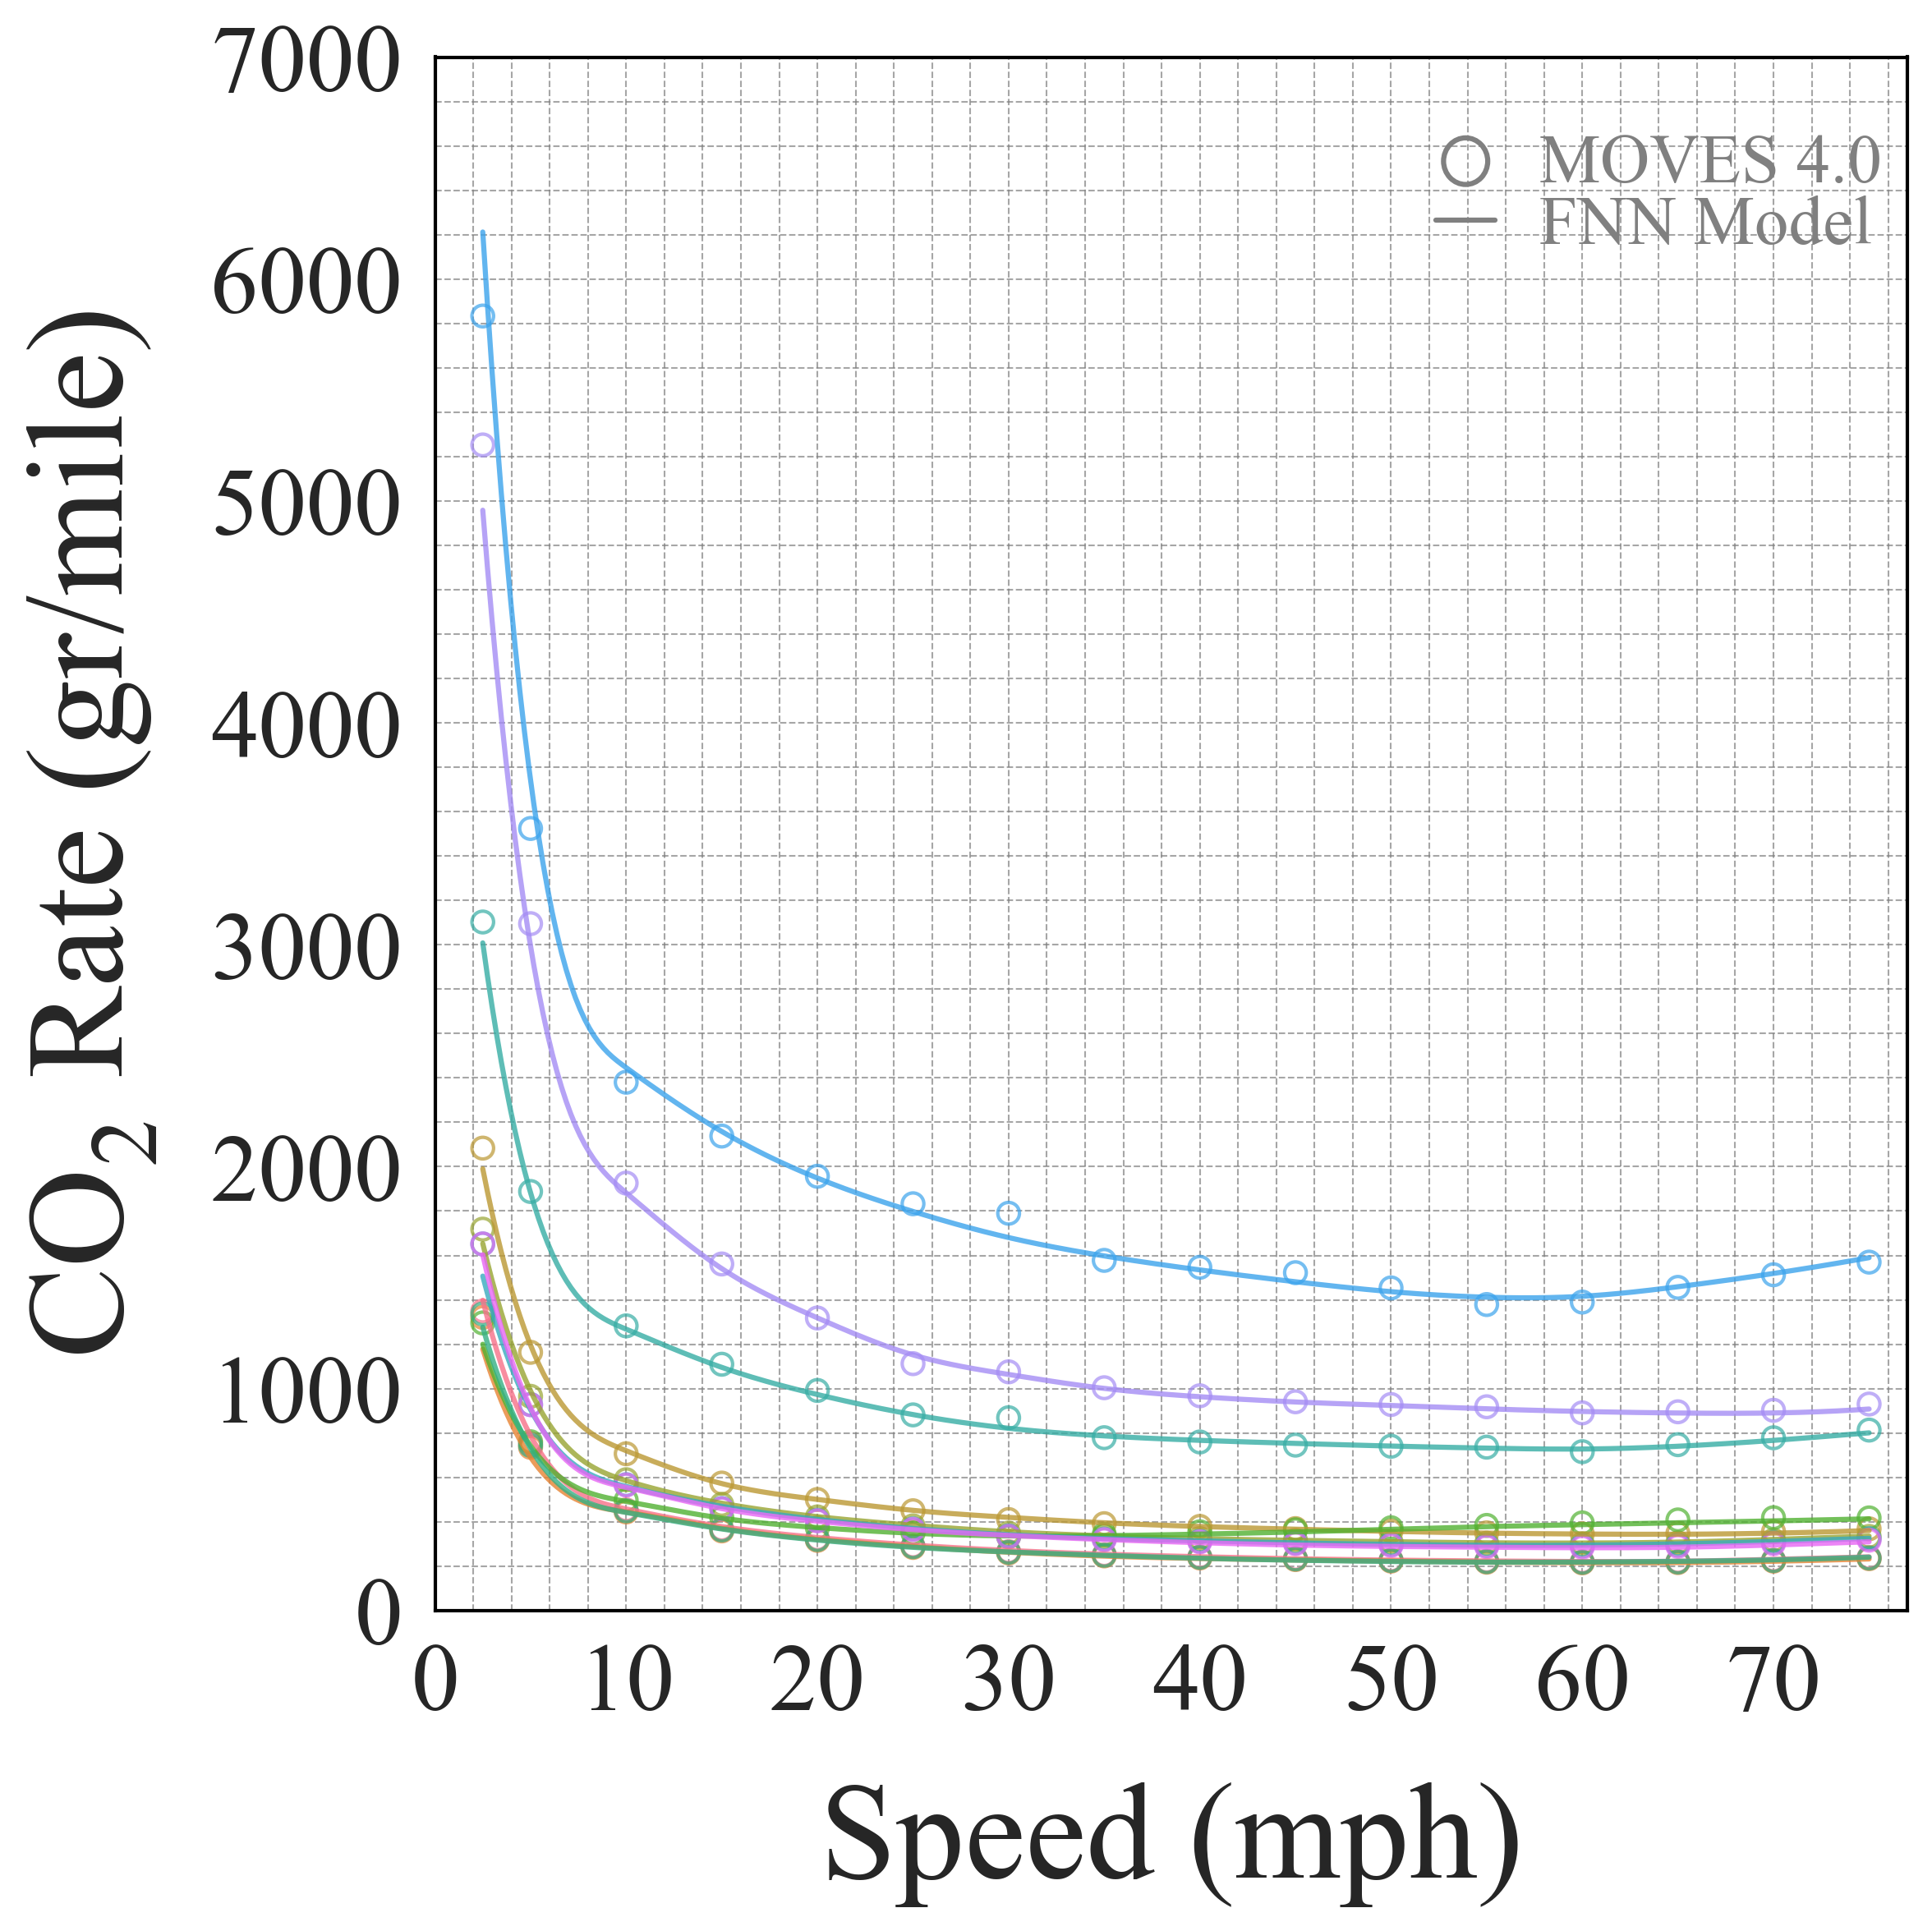

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline
import numpy as np
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

# Load the dataset
file_path = r'C:\Users\schowdho\Downloads\NY\Paper Plot\Fig 3\CA\2024CaliforniaMovesdata_sorted_above_CO2.csv'
data = pd.read_csv(file_path)

# Function to filter data and plot with enhanced legend and continuous lines using spline interpolation
def plot_all_data_continuous_spline(vehicle_groups, age, xlabel_pad=10, ylabel_pad=10, xlabel_size=12, ylabel_size=12, xtick_size=10, ytick_size=10, annotation_size=12, xlim=None, ylim=None, save_path=None):
    # Set the plot style
    sns.set(style="whitegrid")

    # Set the font to Times New Roman
    plt.rcParams["font.family"] = "Times New Roman"
    
    # Filter data for the specified age
    age_data = data[data['Age'] == age]

    # Create the plot with the specified styles
    fig, ax = plt.subplots(figsize=(8, 8), dpi=300)  # EnhancedPlot: Changed from plt.figure to fig, ax with dpi=300

    colors = sns.color_palette("husl", len(vehicle_groups))
    scatter_lines = []
    for idx, (vehicle_type, fuel_type) in enumerate(vehicle_groups):
        subset = age_data[(age_data['Vehicle Type'] == vehicle_type) & (age_data['Fuel Type'] == fuel_type)]
        if not subset.empty:
            subset = subset.sort_values(by='Speed')  # Ensure data is sorted by speed
            scatter = plt.scatter(subset['Speed'], subset['CO2'], 
                        label=f'{vehicle_type} - {fuel_type}', color=colors[idx], marker='o', facecolors='none', edgecolors=colors[idx], alpha=0.7, s=40)  # EnhancedPlot: Changed marker style and added facecolors, edgecolors, and alpha
            
            # Spline interpolation for smooth curve
            x_new = np.linspace(subset['Speed'].min(), subset['Speed'].max(), 300) 
            spline = make_interp_spline(subset['Speed'], subset['Predicted CO2'], k=3)
            y_smooth = spline(x_new)
            
            plt.plot(x_new, y_smooth, linestyle='-', color=colors[idx], linewidth=1.5, alpha=0.8)  # EnhancedPlot: Removed label='_nolegend_' and added linestyle and alpha
            scatter_lines.append((scatter, plt.Line2D([], [], color=colors[idx], linewidth=1.5), f'{vehicle_type} - {fuel_type}'))
            print(f'Plotted data for: {vehicle_type} - {fuel_type}')
        else:
            print(f'No data found for: {vehicle_type} - {fuel_type}')

    # Adding labels with padding and text size
    plt.xlabel('Speed (mph)', labelpad=xlabel_pad, fontsize=xlabel_size)
    plt.ylabel(r'$\mathregular{CO_2}$ Rate (gr/mile)', labelpad=ylabel_pad, fontsize=ylabel_size)
    
    # Set the plot limits if provided
    if xlim:
        plt.xlim(xlim)
    if ylim:
        plt.ylim(ylim)

    # Set the tick label sizes
    plt.xticks(fontsize=xtick_size)
    plt.yticks(fontsize=ytick_size)
    
    # Set the box border color to dark black
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)  # Adjust the width if necessary

    # Add annotation with aligned text for MOVES 4.0 and FNN Model
    circle = Circle((0.70, 0.933), 0.015, transform=ax.transAxes, fill=False, edgecolor='gray', linewidth=1.5)  # EnhancedPlot: Added Circle
    ax.add_patch(circle)
    line = Line2D([0.68, 0.72], [0.895, 0.895], transform=ax.transAxes, color='gray', linewidth=1.5)  # EnhancedPlot: Added Line2D
    ax.add_line(line)
    ax.annotate('MOVES 4.0', xy=(0.75, 0.92), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='left')  # EnhancedPlot: Changed annotation positions
    ax.annotate('FNN Model', xy=(0.75, 0.88), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='left')  # EnhancedPlot: Changed annotation positions

    # Enable major and minor grid lines
    ax.grid(True, color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
    ax.minorticks_on()
    ax.grid(which='minor', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)

    plt.tight_layout()
    
    # Save the plot as an SVG file if a save path is provided
    if save_path:
        plt.savefig(save_path, format='svg')
    
    plt.show()

# Manually input vehicle type and fuel type groups
vehicle_fuel_groups = [
    ('Passenger Car', 'Gasoline'),
    ('Passenger Car', 'Ethanol (E-85)'),
    ('Light Commercial Truck', 'Gasoline'),
    ('Passenger Truck', 'Gasoline'),
    ('Motorcycle', 'Gasoline'),
    ('Passenger Car', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Diesel Fuel'),
    ('Passenger Truck', 'Ethanol (E-85)'),
    ('Combination Long-haul Truck', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Gasoline'),
    ('Light Commercial Truck', 'Ethanol (E-85)'),
    ('Passenger Car', 'Electricity')
]

# Specify the save path
save_path = r'C:\Users\schowdho\Downloads\GA1\PLOT FIGURE\Fig_2_b_2.svg'

# Plot data for the specified groups at Age 2 with continuous spline interpolation and customized text sizes
plot_all_data_continuous_spline(vehicle_fuel_groups, age=2, xlabel_pad=15, ylabel_pad=15, xlabel_size=40, ylabel_size=40, xtick_size=28, ytick_size=28, annotation_size=20, xlim=(0, 77), ylim=(0, 7000), save_path=save_path)


Plotted data for: Passenger Car - Gasoline
Plotted data for: Passenger Car - Ethanol (E-85)
Plotted data for: Light Commercial Truck - Gasoline
Plotted data for: Passenger Truck - Gasoline
Plotted data for: Motorcycle - Gasoline
Plotted data for: Passenger Car - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Diesel Fuel
Plotted data for: Passenger Truck - Ethanol (E-85)
Plotted data for: Combination Long-haul Truck - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Gasoline
Plotted data for: Light Commercial Truck - Ethanol (E-85)
No data found for: Passenger Car - Electricity


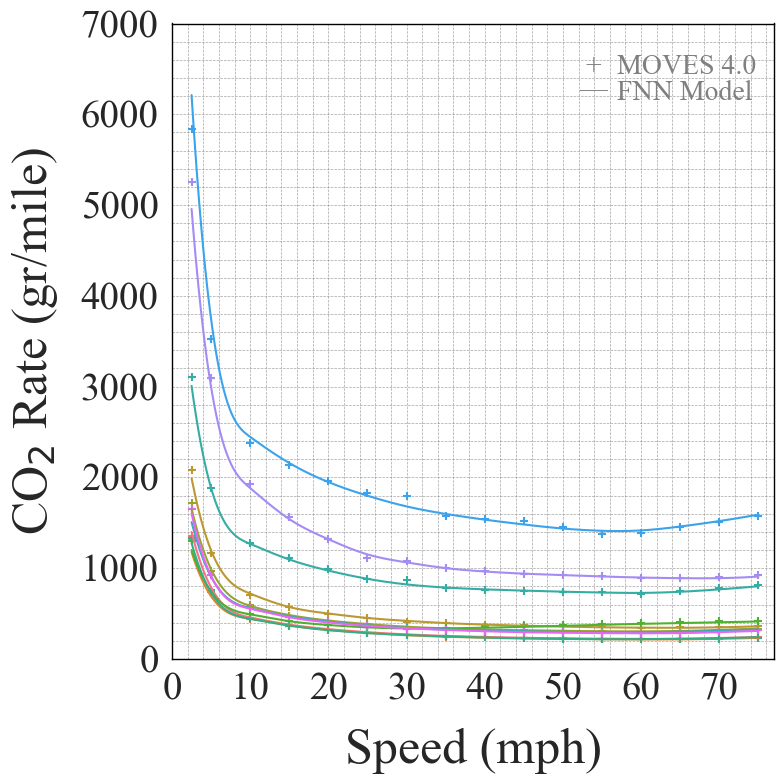

In [3]:
#Used in TRB Paper

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline
import numpy as np
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

# Load the dataset
file_path = r'C:\Users\schowdho\Downloads\NY\Paper Plot\Fig 3\CA\2024CaliforniaMovesdata_sorted_above_CO2.csv'
data = pd.read_csv(file_path)

# Function to filter data and plot with enhanced legend and continuous lines using spline interpolation
def plot_all_data_continuous_spline(vehicle_groups, age, xlabel_pad=10, ylabel_pad=10, xlabel_size=12, ylabel_size=12, xtick_size=10, ytick_size=10, annotation_size=12, xlim=None, ylim=None, save_path=None):
    # Set the plot style
    sns.set(style="whitegrid")

    # Set the font to Times New Roman
    plt.rcParams["font.family"] = "Times New Roman"

    # Filter data for the specified age
    age_data = data[data['Age'] == age]

    # Create the plot with the specified styles
    plt.figure(figsize=(8, 8))  # Set the figure size to make the plot square

    colors = sns.color_palette("husl", len(vehicle_groups))
    scatter_lines = []
    for idx, (vehicle_type, fuel_type) in enumerate(vehicle_groups):
        subset = age_data[(age_data['Vehicle Type'] == vehicle_type) & (age_data['Fuel Type'] == fuel_type)]
        if not subset.empty:
            subset = subset.sort_values(by='Speed')  # Ensure data is sorted by speed
            scatter = plt.scatter(subset['Speed'], subset['CO2'], 
                        label=f'{vehicle_type} - {fuel_type}', color=colors[idx], marker='+', s=40)
            
            # Spline interpolation for smooth curve
            x_new = np.linspace(subset['Speed'].min(), subset['Speed'].max(), 300) 
            spline = make_interp_spline(subset['Speed'], subset['Predicted CO2'], k=3)
            y_smooth = spline(x_new)
            
            plt.plot(x_new, y_smooth, color=colors[idx], linewidth=1.5, label='_nolegend_')
            scatter_lines.append((scatter, plt.Line2D([], [], color=colors[idx], linewidth=1.5), f'{vehicle_type} - {fuel_type}'))
            print(f'Plotted data for: {vehicle_type} - {fuel_type}')
        else:
            print(f'No data found for: {vehicle_type} - {fuel_type}')

    # Adding labels with padding and text size
    plt.xlabel('Speed (mph)', labelpad=xlabel_pad, fontsize=xlabel_size)
    plt.ylabel('CO$_2$ Rate (gr/mile)', labelpad=ylabel_pad, fontsize=ylabel_size)
    
    # Set the plot limits if provided
    if xlim:
        plt.xlim(xlim)
    if ylim:
        plt.ylim(ylim)

    # Set the tick label sizes
    plt.xticks(fontsize=xtick_size)
    plt.yticks(fontsize=ytick_size)
    
    # Set the box border color to dark black
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)  # Adjust the width if necessary
    
    # Remove legend plotting
    # Add annotation with aligned text for MOVES 4.0 and FNN Model
    ax.annotate('+', xy=(0.70, 0.92), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='center')
    ax.annotate('—', xy=(0.70, 0.885), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='center')
    ax.annotate('MOVES 4.0', xy=(0.74, 0.92), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='left')
    ax.annotate('FNN Model', xy=(0.74, 0.88), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='left')

    # Enable major and minor grid lines
    ax.grid(True, color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
    ax.minorticks_on()
    ax.grid(which='minor', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)

    plt.tight_layout()
    
    # Save the plot as an SVG file if a save path is provided
    if save_path:
        plt.savefig(save_path, format='svg')
    
    plt.show()

# Manually input vehicle type and fuel type groups
vehicle_fuel_groups = [
    ('Passenger Car', 'Gasoline'),
    ('Passenger Car', 'Ethanol (E-85)'),
    ('Light Commercial Truck', 'Gasoline'),
    ('Passenger Truck', 'Gasoline'),
    ('Motorcycle', 'Gasoline'),
    ('Passenger Car', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Diesel Fuel'),
    ('Passenger Truck', 'Ethanol (E-85)'),
    ('Combination Long-haul Truck', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Gasoline'),
    ('Light Commercial Truck', 'Ethanol (E-85)'),
    ('Passenger Car', 'Electricity')
]

# Specify the save path
save_path = r'C:\Users\schowdho\Downloads\GA1\PLOT FIGURE\Fig_2_b_2.svg'

# Plot data for the specified groups at Age 2 with continuous spline interpolation and customized text sizes
plot_all_data_continuous_spline(vehicle_fuel_groups, age=2, xlabel_pad=15, ylabel_pad=15, xlabel_size=36, ylabel_size=36, xtick_size=28, ytick_size=28, annotation_size=20, xlim=(0, 77), ylim=(0, 7000), save_path=save_path)


Plotted data for: Passenger Car - Gasoline
Plotted data for: Passenger Car - Ethanol (E-85)
Plotted data for: Light Commercial Truck - Gasoline
Plotted data for: Passenger Truck - Gasoline
Plotted data for: Motorcycle - Gasoline
Plotted data for: Passenger Car - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Diesel Fuel
Plotted data for: Passenger Truck - Ethanol (E-85)
Plotted data for: Combination Long-haul Truck - Diesel Fuel
Plotted data for: Single Unit Short-haul Truck - Gasoline
Plotted data for: Light Commercial Truck - Ethanol (E-85)
No data found for: Passenger Car - Electricity


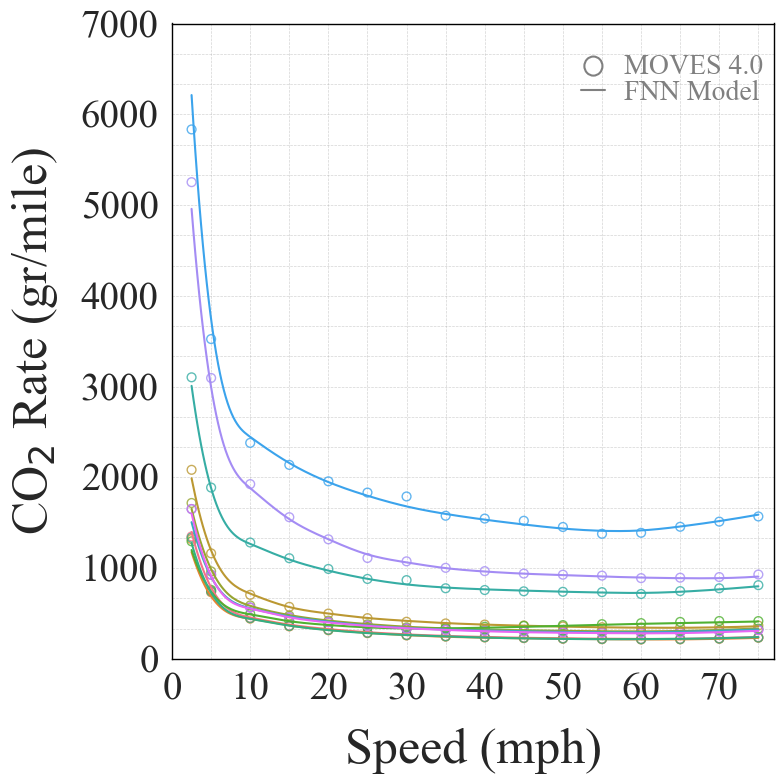

In [1]:
#Version 2 

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline
import numpy as np
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.ticker import AutoMinorLocator

# Load the dataset
file_path = r'C:\Users\schowdho\Downloads\NY\Paper Plot\Fig 3\CA\2024CaliforniaMovesdata_sorted_above_CO2.csv'
data = pd.read_csv(file_path)

# Function to filter data and plot with enhanced legend and continuous lines using spline interpolation
def plot_all_data_continuous_spline(vehicle_groups, age, xlabel_pad=10, ylabel_pad=10, xlabel_size=12, ylabel_size=12, xtick_size=10, ytick_size=10, annotation_size=12, xlim=None, ylim=None, save_path=None):
    # Set the plot style
    sns.set(style="whitegrid")

    # Set the font to Times New Roman
    plt.rcParams["font.family"] = "Times New Roman"

    # Filter data for the specified age
    age_data = data[data['Age'] == age]

    # Create the plot with the specified styles
    plt.figure(figsize=(8, 8))  # Set the figure size to make the plot square

    colors = sns.color_palette("husl", len(vehicle_groups))
    scatter_lines = []
    for idx, (vehicle_type, fuel_type) in enumerate(vehicle_groups):
        subset = age_data[(age_data['Vehicle Type'] == vehicle_type) & (age_data['Fuel Type'] == fuel_type)]
        if not subset.empty:
            subset = subset.sort_values(by='Speed')  # Ensure data is sorted by speed
            scatter = plt.scatter(subset['Speed'], subset['CO2'], 
                        label=f'{vehicle_type} - {fuel_type}', color=colors[idx], marker='o', s=40, facecolors='none', edgecolors=colors[idx], alpha=0.8)
            
            # Spline interpolation for smooth curve
            x_new = np.linspace(subset['Speed'].min(), subset['Speed'].max(), 300) 
            spline = make_interp_spline(subset['Speed'], subset['Predicted CO2'], k=3)
            y_smooth = spline(x_new)
            
            plt.plot(x_new, y_smooth, color=colors[idx], linewidth=1.5, label='_nolegend_')
            scatter_lines.append((scatter, plt.Line2D([], [], color=colors[idx], linewidth=1.5), f'{vehicle_type} - {fuel_type}'))
            print(f'Plotted data for: {vehicle_type} - {fuel_type}')
        else:
            print(f'No data found for: {vehicle_type} - {fuel_type}')

    # Adding labels with padding and text size
    plt.xlabel('Speed (mph)', labelpad=xlabel_pad, fontsize=xlabel_size)
    plt.ylabel('CO$_2$ Rate (gr/mile)', labelpad=ylabel_pad, fontsize=ylabel_size)
    
    # Set the plot limits if provided
    if xlim:
        plt.xlim(xlim)
    if ylim:
        plt.ylim(ylim)

    # Set the tick label sizes
    plt.xticks(fontsize=xtick_size)
    plt.yticks(fontsize=ytick_size)
    
    # Set the box border color to dark black
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)  # Adjust the width if necessary
    
    # Remove legend plotting
    # Add annotation with aligned text for MOVES 4.0 and FNN Model
    circle = Circle((0.70, 0.933), 0.015, transform=ax.transAxes, fill=False, edgecolor='gray', linewidth=1.5)
    ax.add_patch(circle)
    line = Line2D([0.68, 0.72], [0.895, 0.895], transform=ax.transAxes, color='gray', linewidth=1.5)
    ax.add_line(line)
    ax.annotate('MOVES 4.0', xy=(0.75, 0.92), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='left')
    ax.annotate('FNN Model', xy=(0.75, 0.88), xycoords='axes fraction', fontsize=annotation_size, color='gray', ha='left')

    # Enable major and minor grid lines
    ax.grid(True, color='darkgray', linestyle='--', linewidth=0.5, alpha=0.5)
    
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(3))
    
    ax.grid(which='minor', color='darkgray', linestyle='--', linewidth=0.5, alpha=0.5)

    plt.tight_layout()
    
    # Save the plot as an SVG file if a save path is provided
    if save_path:
        plt.savefig(save_path, format='svg')
    
    plt.show()

# Manually input vehicle type and fuel type groups
vehicle_fuel_groups = [
    ('Passenger Car', 'Gasoline'),
    ('Passenger Car', 'Ethanol (E-85)'),
    ('Light Commercial Truck', 'Gasoline'),
    ('Passenger Truck', 'Gasoline'),
    ('Motorcycle', 'Gasoline'),
    ('Passenger Car', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Diesel Fuel'),
    ('Passenger Truck', 'Ethanol (E-85)'),
    ('Combination Long-haul Truck', 'Diesel Fuel'),
    ('Single Unit Short-haul Truck', 'Gasoline'),
    ('Light Commercial Truck', 'Ethanol (E-85)'),
    ('Passenger Car', 'Electricity')
]

# Specify the save path
save_path = r'C:\Users\schowdho\Downloads\GA1\PLOT FIGURE\Version 2\Fig_2_b_2.svg'

# Plot data for the specified groups at Age 2 with continuous spline interpolation and customized text sizes
plot_all_data_continuous_spline(vehicle_fuel_groups, age=2, xlabel_pad=15, ylabel_pad=15, xlabel_size=36, ylabel_size=36, xtick_size=28, ytick_size=28, annotation_size=20, xlim=(0, 77), ylim=(0, 7000), save_path=save_path)
